In [1]:
import time
import matplotlib.pyplot as plt
import numpy as np
from scipy.optimize import curve_fit
from fooof import FOOOF

## Simulate

In [2]:
freqs = np.linspace(1, 100, 200)

# Aperiodic
def aperiodic_func(freqs, knee_freqs, exp, offset):
    return offset + (1/((knee_freq**(exp)) + (freqs)**exp))

knee_freq, exp, offset = 10, 2, 0 
powers = aperiodic_func(freqs, knee_freq, exp, offset)

# Periodic
np.random.seed(0)
peak_params = [
    # Large low freq peak
    [.05, 20, 6],
    # Random small high freq peaks
    *[[np.random.rand()*5e-4, cf, 1] for cf in np.arange(55, 80, 5)]
]

peaks = np.zeros_like(freqs)
for h, cf, sd in peak_params:
    peaks += h * np.exp(-((freqs-cf)**2)/(2*(sd**2)))
    
# Combine
powers = powers + peaks

## Iterative Optimization

Below, an iterative optimization method is used to gradually remove outliers. At each iteration, power above the fit is removed from the next iteration. This means that power above the aperiodic (e.g. oscillations) is iterativly removed resulting in improved aperiodic fits.

Elapsed time: 0.004484891891479492s


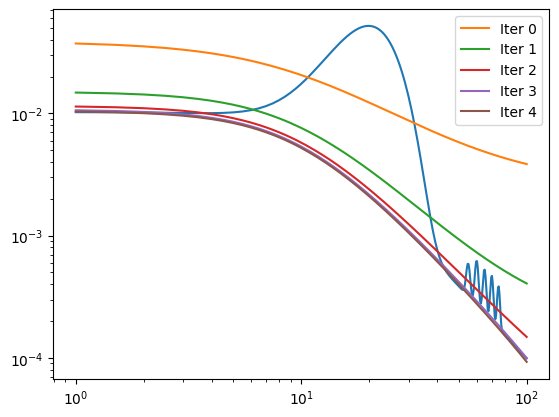

In [4]:
freqs_sub = freqs.copy()
powers_sub = powers.copy()

params_all = []
eps = 1e-6

start = time.time()
for _ in range(5):
    
    # Estimate params
    params, _ = curve_fit(aperiodic_func, freqs_sub, powers_sub)
    
    # Generate fit
    fit = aperiodic_func(freqs_sub, *params)
    
    # Remove power above the fit
    inds = np.where(powers_sub-eps < fit)[0]
    freqs_sub = freqs_sub[inds]
    powers_sub = powers_sub[inds]
    
    # Track history of learned parameters
    params_all.append(params)

end = time.time()
    
print(f'Elapsed time: {end-start}s')

# Plot
plt.loglog(freqs, powers)
for i, p in enumerate(params_all):
    plt.loglog(freqs, aperiodic_func(freqs, *p),
               label=f'Iter {i}')
plt.legend();

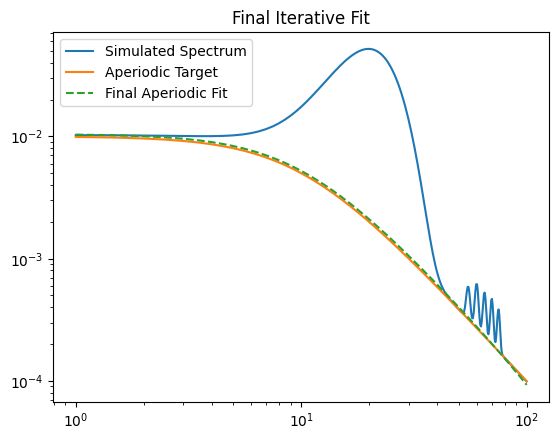

In [5]:
plt.title('Final Iterative Fit')
plt.loglog(freqs, powers, label='Simulated Spectrum')
plt.loglog(freqs, powers-peaks, label='Aperiodic Target')
plt.loglog(freqs, aperiodic_func(freqs, *params), label=f'Final Aperiodic Fit', ls='--')
plt.legend();

# SpecParam

There is currently no automatic tuning in `SpecParam` that could allow accurate aperiodic fits in these simulations. Instead `SpecParam` would rely on accurate param guesses and bounds that the users must specify apriori. `SpecParam` fits an inital aperiodic fit (non-robustly using linear least squares), followed by Gaussian peaks from the aperiodic removed spectrum, and lastly a re-fit of the aperiodic spectrum with the peaks removed. Without accurate initial parameters estimates and bounds, the initial non-robust fit will inherently bias subsequent fits.

Elapsed time: 0.046282052993774414s


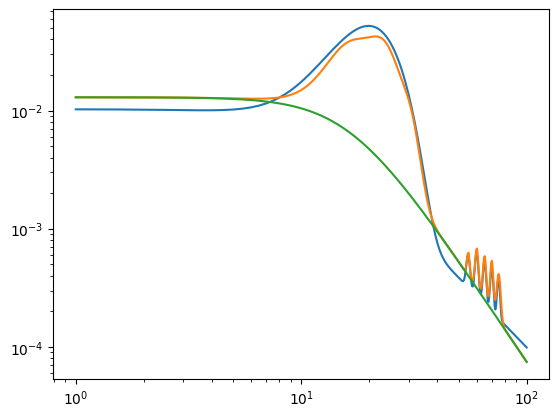

In [7]:
# SpecParam
start = time.time()
fm = FOOOF(aperiodic_mode='knee', verbose=False)
fm.fit(freqs, powers)
end = time.time()

print(f'Elapsed time: {end-start}s')

# Plot
plt.loglog(freqs, powers, label='Simulated Spectrum')
plt.loglog(freqs, 10**fm.fooofed_spectrum_, label='Full Fit')
plt.loglog(freqs, 10**fm._ap_fit, label='Aperiodic Fit');